<a href="https://colab.research.google.com/github/varsha04092007/Language_Identification/blob/main/Language_Identification_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files

uploaded = files.upload()

Saving dataset.csv to dataset.csv


In [18]:
import os
import re
import random
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

# Load your CSV file
df = pd.read_csv("/content/dataset.csv")

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print(df.head())

TensorFlow version: 2.21.0
Dataset shape: (22000, 2)
Column names: ['Text', 'language']
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [19]:
# Remove extra spaces and normalize column names
df.columns = df.columns.astype(str).str.strip()

# Map lowercase column names to original column names
column_map = {
    col.lower().strip(): col for col in df.columns
}

text_candidates = ["text", "sentence", "content", "texts"]
language_candidates = [
    "language", "label", "lang", "language_name", "languages"
]

text_col = next(
    (column_map[c] for c in text_candidates if c in column_map),
    None
)

language_col = next(
    (column_map[c] for c in language_candidates if c in column_map),
    None
)

if text_col is None or language_col is None:
    raise ValueError(
        "Could not identify text and language columns. "
        f"Available columns: {df.columns.tolist()}"
    )

# Rename to standard names
df = df.rename(columns={
    text_col: "Text",
    language_col: "Language"
})

df = df[["Text", "Language"]].copy()

# Handle missing values
df = df.dropna(subset=["Text", "Language"])

# Convert to strings and remove extra spaces
df["Text"] = df["Text"].astype(str).str.strip()
df["Language"] = df["Language"].astype(str).str.strip()

# Remove empty entries and duplicate rows
df = df[
    (df["Text"] != "") &
    (df["Language"] != "")
].drop_duplicates()

df = df.reset_index(drop=True)

print("Columns detected successfully!")
print("Dataset shape:", df.shape)
print("\nLanguage counts:")
print(df["Language"].value_counts())
print("\nSample data:")
print(df.head())

Columns detected successfully!
Dataset shape: (21858, 2)

Language counts:
Language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64

Sample data:
                                                Text  Language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [20]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["Text"] = df["Text"].apply(clean_text)

df = df[df["Text"] != ""].reset_index(drop=True)

# Keep up to 30,000 samples
MAX_SAMPLES = 30000

if len(df) > MAX_SAMPLES:
    df, _ = train_test_split(
        df,
        train_size=MAX_SAMPLES,
        random_state=SEED,
        stratify=df["Language"]
    )

df = df.reset_index(drop=True)

print("Samples selected:", len(df))
print("Number of languages:", df["Language"].nunique())

Samples selected: 21858
Number of languages: 22


In [21]:
df = df.sample(
    n=min(30000, len(df)),
    random_state=SEED
).reset_index(drop=True)

print("Samples selected:", len(df))

Samples selected: 21858


In [22]:
label_encoder = LabelEncoder()

df["Language_ID"] = label_encoder.fit_transform(df["Language"])

X = df["Text"].to_numpy()
y = df["Language_ID"].to_numpy()

num_classes = len(label_encoder.classes_)

print("Number of language classes:", num_classes)
print("Language names:", label_encoder.classes_)

Number of language classes: 22
Language names: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 17486
Testing samples: 4372


In [24]:
MAX_WORDS = 20000
MAX_LENGTH = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training padded shape:", X_train_pad.shape)
print("Testing padded shape:", X_test_pad.shape)
print("Example sequence:", X_train_pad[0][:20])

Training padded shape: (17486, 100)
Testing padded shape: (4372, 100)
Example sequence: [  343 11637 13217     1   148     1  2948     1  5201     1     1  4881
     1  4882     1  2949     1     1     1   148]


In [25]:
model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [26]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 35s 125ms/step - accuracy: 0.4151 - loss: 2.0254 - val_accuracy: 0.6123 - val_loss: 1.4075
Epoch 2/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - accuracy: 0.7638 - loss: 0.8671 - val_accuracy: 0.8033 - val_loss: 0.6367
Epoch 3/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - accuracy: 0.8582 - loss: 0.5221 - val_accuracy: 0.7604 - val_loss: 0.7816
Epoch 4/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 44s 124ms/step - accuracy: 0.8624 - loss: 0.4574 - val_accuracy: 0.9051 - val_loss: 0.2861
Epoch 5/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 44s 181ms/step - accuracy: 0.9147 - loss: 0.2785 - val_accuracy: 0.9137 - val_loss: 0.2630
Epoch 6/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 66s 115ms/step - accuracy: 0.9257 - loss: 0.2247 - val_accuracy: 0.9114 - val_loss: 0.2471
Epoch 7/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 40s 111ms/step - accuracy: 0.9330 - loss: 0.1882 - val_accuracy: 0.9188 - val_loss: 0.2212
Epoch 8/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 41s 112ms/step - accuracy: 0.9376 - loss: 0

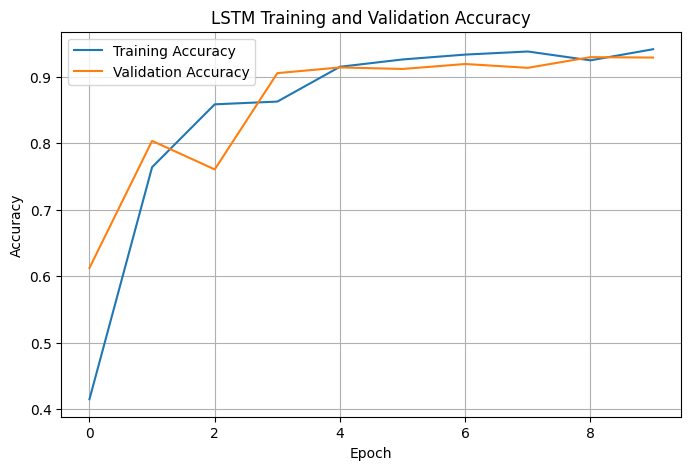

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

Accuracy : 0.9231
Precision: 0.9194
Recall   : 0.9234
F1-score : 0.9143

Detailed classification report:
              precision    recall  f1-score   support

      Arabic       0.99      0.98      0.99       200
     Chinese       0.30      0.05      0.09       200
       Dutch       1.00      0.98      0.99       199
     English       0.89      0.96      0.93       200
    Estonian       0.98      0.94      0.96       200
      French       0.98      0.98      0.98       198
       Hindi       0.99      0.96      0.98       198
  Indonesian       0.99      0.98      0.98       195
    Japanese       0.47      0.87      0.61       200
      Korean       0.99      0.99      0.99       200
       Latin       0.96      0.95      0.96       191
     Persian       1.00      0.99      0.99       200
   Portugese       0.98      0.98      0.98       199
      Pushto       0.95      0.96      0.95       199
    Romanian       0.99      0.97      0.98       200
     Russian       0.99      0

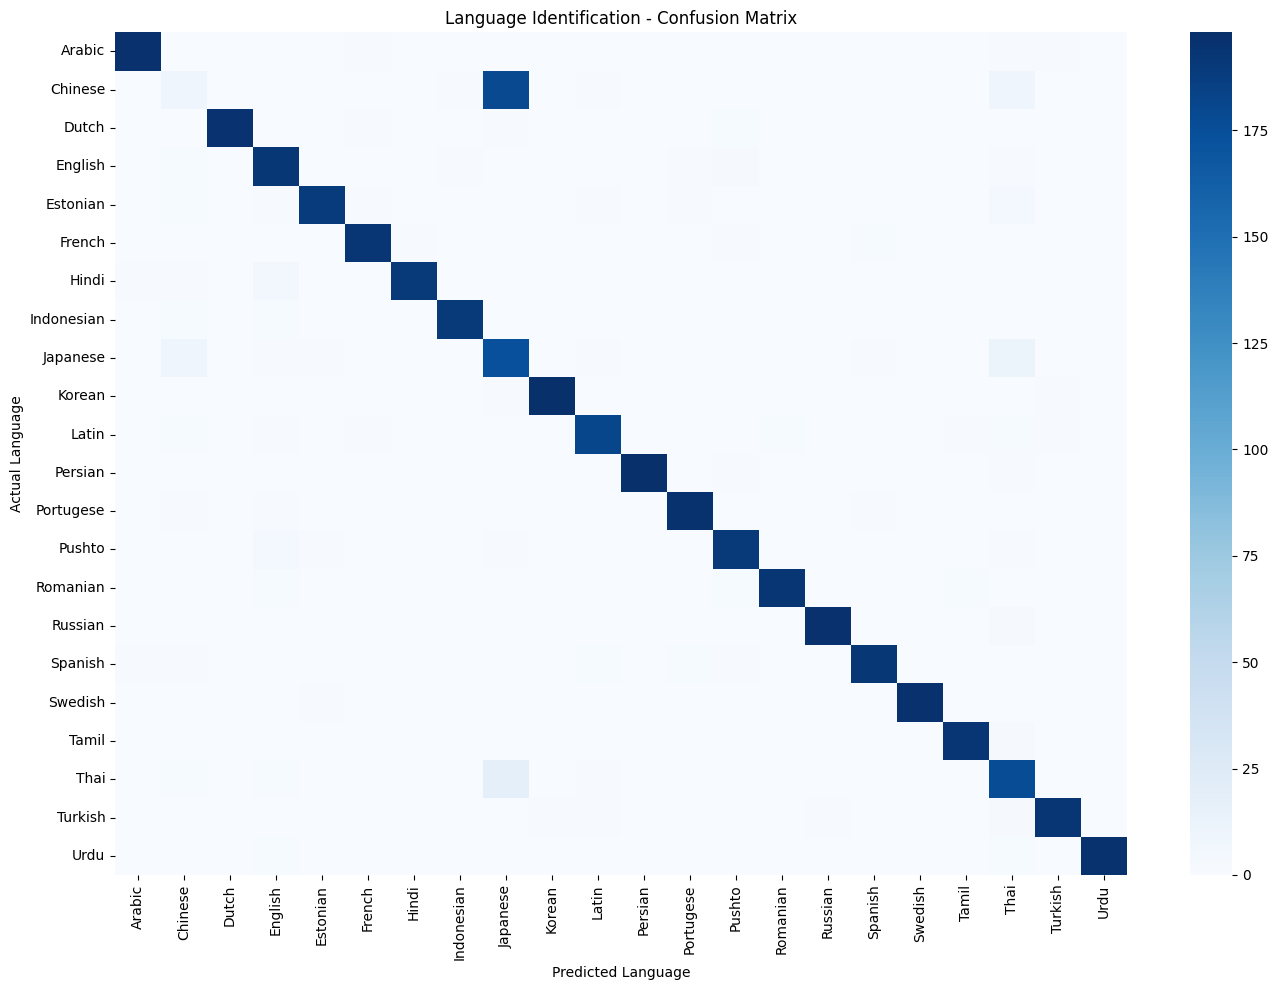

In [29]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Language Identification - Confusion Matrix")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
def predict_language(text):
    cleaned = clean_text(text)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))

    language = label_encoder.inverse_transform(
        [predicted_id]
    )[0]

    confidence = float(probabilities[predicted_id]) * 100

    return language, confidence


unseen_samples = [
    "Hello, how are you today?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "नमस्ते, आप कैसे हैं?"
]

for text in unseen_samples:
    language, confidence = predict_language(text)

    print("Input text:", text)
    print("Predicted language:", language)
    print(f"Model confidence: {confidence:.2f}%")
    print("-" * 45)

Input text: Hello, how are you today?
Predicted language: Chinese
Model confidence: 41.47%
---------------------------------------------
Input text: Bonjour, comment allez-vous ?
Predicted language: Japanese
Model confidence: 29.49%
---------------------------------------------
Input text: Hola, ¿cómo estás?
Predicted language: Japanese
Model confidence: 48.66%
---------------------------------------------
Input text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted language: Japanese
Model confidence: 46.43%
---------------------------------------------
Input text: नमस्ते, आप कैसे हैं?
Predicted language: Chinese
Model confidence: 34.76%
---------------------------------------------


In [31]:
model.save("/content/language_identification_lstm.keras")

with open("/content/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("/content/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

print("Model and preprocessing files saved successfully.")

Model and preprocessing files saved successfully.
